# 06: Cross-Model Comparison & Tokenizer Efficiency Analysis
**Course**: Foundations of Generative AI (ICT4403) - Assignment 3  
**Models Compared**:
- Model A: Basic Transformer (from scratch)
- Model B: mT5-small (full fine-tune)
- Model C: LLaMA-3.2-1B-Instruct (4-bit QLoRA & Zero-Shot)
- Model D: Gemma (4-bit QLoRA & Zero-Shot)

### Objectives
1. Ingest all evaluation metric JSONs from `results/metrics/`.
2. Compile the comprehensive cross-model comparison table.
3. Perform **Empirical Tokenization Efficiency Analysis**: quantify subword token inflation for Hindi across all four tokenizers on the real test references.
4. Generate publication-ready comparison charts: BLEU/chrF bars, parameter efficiency, training time trade-offs, and inference latency.
5. Programmatically identify Pareto-optimal and winning models.

## 1. Environment Setup & Load Artifacts

In [1]:
import os
import sys
import glob
import json
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np

DRIVE_DIR = "/content/drive/MyDrive/mt-fgai-assignment3"

try:
    from google.colab import drive
    print("Mounting Google Drive...")
    drive.mount("/content/drive")
    os.makedirs(DRIVE_DIR, exist_ok=True)
    print(f"Google Drive ready at: {DRIVE_DIR}")
except ImportError:
    print("Running locally.")
    DRIVE_DIR = "."

if os.path.exists(DRIVE_DIR) and os.path.exists(os.path.join(DRIVE_DIR, "configs", "config.yaml")):
    REPO_ROOT = DRIVE_DIR
    os.chdir(REPO_ROOT)
    print(f"Active project root set to Google Drive: {REPO_ROOT}")
else:
    REPO_ROOT = os.path.abspath(".")

if REPO_ROOT not in sys.path:
    sys.path.insert(0, REPO_ROOT)

try:
    import google.colab
    !pip install -q transformers>=4.45.0 accelerate peft trl bitsandbytes sentencepiece sacrebleu evaluate datasets pyyaml tabulate
except ImportError:
    pass

# Retrieve Hugging Face token for tokenizer access
hf_token = os.environ.get("HF_TOKEN", None)
try:
    from google.colab import userdata
    hf_token = userdata.get("HF_TOKEN")
    print("Successfully authenticated using Colab Secret HF_TOKEN.")
except Exception:
    if hf_token:
        print("Using HF_TOKEN from environment variables.")
    else:
        print("Warning: HF_TOKEN not found.")

os.makedirs("results/plots", exist_ok=True)

from src.make_report import load_all_metrics, build_comparison_dataframe

records = load_all_metrics("results/metrics")
print(f"Found {len(records)} metric files in results/metrics/")
df_comp = build_comparison_dataframe(records)
df_comp

Mounting Google Drive...
Mounted at /content/drive
Google Drive ready at: /content/drive/MyDrive/mt-fgai-assignment3
Active project root set to Google Drive: /content/drive/MyDrive/mt-fgai-assignment3
Successfully authenticated using Colab Secret HF_TOKEN.
Found 6 metric files in results/metrics/


,Model,Architecture,Adaptation,Total Params,Trainable Params,Train Pairs,BLEU,chrF,chrF++,Train Time (s),Inference (ms/sent)
0,google/gemma-3-1b-it_qlora,decoder_only,qlora_4bit,"664,050,816","13,045,760","2,500",11.10,35.93,34.06,353.4,454.28
1,google/gemma-3-1b-it_zeroshot,decoder_only,zero_shot,"651,005,056",0,0,9.53,33.06,31.18,0.0,198.56
2,llama_3_2_1b_qlora,decoder_only,qlora_4bit,"760,547,328","11,272,192","2,500",8.11,32.26,30.16,332.4,749.98
3,llama_3_2_1b_zeroshot,decoder_only,zero_shot,"749,275,136",0,0,7.11,28.05,26.33,0.0,618.96
4,mt5_small,encoder_decoder,full_finetune,"300,176,768","300,176,768","50,000",2.53,19.23,17.75,354.4,134.02
5,transformer_scratch,encoder_decoder,from_scratch,"13,738,624","13,738,624","50,000",3.00,22.58,21.09,596.9,21.61


## 2. Master Comparison Table

In [2]:
if not df_comp.empty:
    print("\n=== Master Model Comparison Table ===")
    print(df_comp.to_markdown(index=False))
    os.makedirs("results", exist_ok=True)
    df_comp.to_csv("results/comparison_table.csv", index=False)
    with open("results/comparison_table.md", "w", encoding="utf-8") as f:
        f.write(df_comp.to_markdown(index=False))
else:
    print("No metrics JSON files found yet. Run notebooks 01 through 04 first.")


=== Master Model Comparison Table ===
| Model                         | Architecture    | Adaptation    | Total Params   | Trainable Params   | Train Pairs   |   BLEU |   chrF |   chrF++ |   Train Time (s) |   Inference (ms/sent) |
|:------------------------------|:----------------|:--------------|:---------------|:-------------------|:--------------|-------:|-------:|---------:|-----------------:|----------------------:|
| google/gemma-3-1b-it_qlora    | decoder_only    | qlora_4bit    | 664,050,816    | 13,045,760         | 2,500         |  11.1  |  35.93 |    34.06 |            353.4 |                454.28 |
| google/gemma-3-1b-it_zeroshot | decoder_only    | zero_shot     | 651,005,056    | 0                  | 0             |   9.53 |  33.06 |    31.18 |              0   |                198.56 |
| llama_3_2_1b_qlora            | decoder_only    | qlora_4bit    | 760,547,328    | 11,272,192         | 2,500         |   8.11 |  32.26 |    30.16 |            332.4 |                

## 3. Empirical Tokenization Efficiency Analysis (Real Data)
We evaluate how each model's tokenizer segments the exact same 1,000 Hindi test reference sentences.  
This reveals the **subword token inflation** caused by tokenizers trained predominantly on English/Latin text.

In [3]:
from src.data import load_split_from_jsonl
from transformers import AutoTokenizer
from src.tokenizer_sp import JointSentencePieceTokenizer

test_data = load_split_from_jsonl("test", splits_dir=os.path.join(REPO_ROOT, "data", "splits"))
hindi_refs = [x["hi"] for x in test_data]
num_words = [len(s.split()) for s in hindi_refs]
total_words = sum(num_words)

tok_stats = []

# 1. Model A Tokenizer (Custom Joint SentencePiece 16k)
sp_model_file = os.path.join(REPO_ROOT, "data", "spm_joint_16k.model")
if os.path.exists(sp_model_file):
    tok_a = JointSentencePieceTokenizer(sp_model_file)
    lens_a = [len(tok_a.encode(s, add_bos=False, add_eos=False)) for s in hindi_refs]
    tok_stats.append({
        "Model": "Model A (Custom SPM)",
        "Vocab Size": tok_a.vocab_size,
        "Tokenizer Type": "Unigram SPM",
        "Avg Tokens / Sent": round(np.mean(lens_a), 2),
        "Subwords / Word": round(sum(lens_a) / total_words, 2),
    })

# 2. Model B Tokenizer (mT5-small)
try:
    tok_b = AutoTokenizer.from_pretrained("google/mt5-small")
    lens_b = [len(tok_b.encode(s, add_special_tokens=False)) for s in hindi_refs]
    tok_stats.append({
        "Model": "Model B (mT5-small)",
        "Vocab Size": tok_b.vocab_size,
        "Tokenizer Type": "Multilingual SPM",
        "Avg Tokens / Sent": round(np.mean(lens_b), 2),
        "Subwords / Word": round(sum(lens_b) / total_words, 2),
    })
except Exception as e:
    print(f"Could not load mT5 tokenizer: {e}")

# 3. Model C Tokenizer (LLaMA-3.2-1B)
try:
    tok_c = AutoTokenizer.from_pretrained("meta-llama/Llama-3.2-1B-Instruct", token=hf_token)
    lens_c = [len(tok_c.encode(s, add_special_tokens=False)) for s in hindi_refs]
    tok_stats.append({
        "Model": "Model C (LLaMA-3.2-1B)",
        "Vocab Size": tok_c.vocab_size,
        "Tokenizer Type": "Byte-level BPE",
        "Avg Tokens / Sent": round(np.mean(lens_c), 2),
        "Subwords / Word": round(sum(lens_c) / total_words, 2),
    })
except Exception as e:
    print(f"Could not load LLaMA tokenizer: {e}")

# 4. Model D Tokenizer (Gemma)
try:
    tok_d = AutoTokenizer.from_pretrained("google/gemma-3-1b-it", token=hf_token)
    lens_d = [len(tok_d.encode(s, add_special_tokens=False)) for s in hindi_refs]
    tok_stats.append({
        "Model": "Model D (Gemma)",
        "Vocab Size": tok_d.vocab_size,
        "Tokenizer Type": "SentencePiece (256k)",
        "Avg Tokens / Sent": round(np.mean(lens_d), 2),
        "Subwords / Word": round(sum(lens_d) / total_words, 2),
    })
except Exception:
    try:
        tok_d = AutoTokenizer.from_pretrained("google/gemma-2-2b-it", token=hf_token)
        lens_d = [len(tok_d.encode(s, add_special_tokens=False)) for s in hindi_refs]
        tok_stats.append({
            "Model": "Model D (Gemma-2)",
            "Vocab Size": tok_d.vocab_size,
            "Tokenizer Type": "SentencePiece (256k)",
            "Avg Tokens / Sent": round(np.mean(lens_d), 2),
            "Subwords / Word": round(sum(lens_d) / total_words, 2),
        })
    except Exception as e:
        print(f"Could not load Gemma tokenizer: {e}")

df_tok = pd.DataFrame(tok_stats)
print("\n--- Tokenization Efficiency on 1,000 Hindi Test Sentences ---")
print(df_tok.to_markdown(index=False))
df_tok.to_csv("results/tokenization_efficiency.csv", index=False)

config.json:   0%|          | 0.00/553 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/82.0 [00:00<?, ?B/s]

spiece.model:   0%|          | 0.00/4.31M [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/99.0 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/877 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/54.5k [00:00<?, ?B/s]

... (5 outputs left out)

tokenizer.json: downloading bytes:           |  0.00B            

added_tokens.json:   0%|          | 0.00/35.0 [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/662 [00:00<?, ?B/s]


--- Tokenization Efficiency on 1,000 Hindi Test Sentences ---
| Model                  |   Vocab Size | Tokenizer Type       |   Avg Tokens / Sent |   Subwords / Word |
|:-----------------------|-------------:|:---------------------|--------------------:|------------------:|
| Model A (Custom SPM)   |        16000 | Unigram SPM          |               28.86 |              1.42 |
| Model B (mT5-small)    |       250100 | Multilingual SPM     |               41.95 |              2.06 |
| Model C (LLaMA-3.2-1B) |       128000 | Byte-level BPE       |               54.97 |              2.7  |
| Model D (Gemma)        |       262144 | SentencePiece (256k) |               27.9  |              1.37 |


## 4. Comparative Visualizations

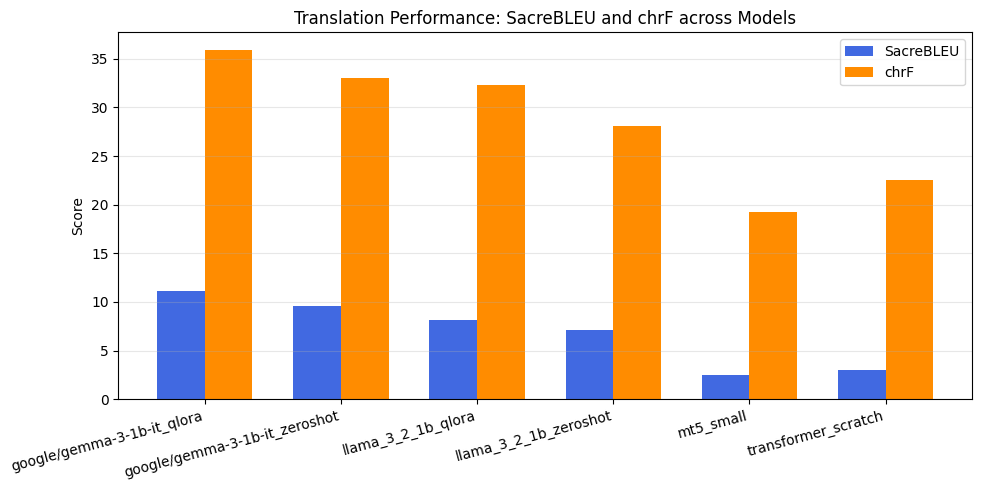

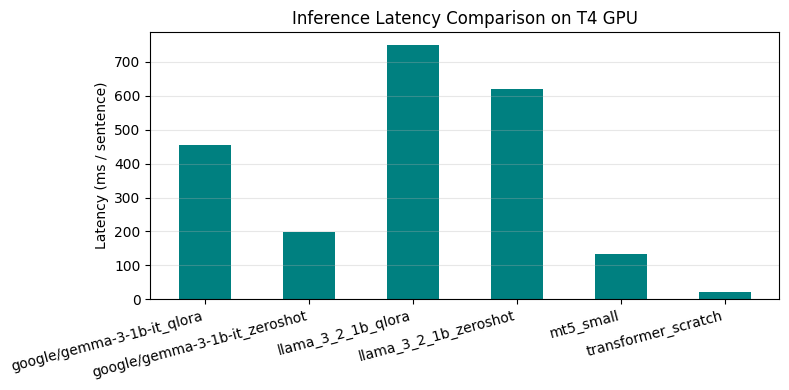

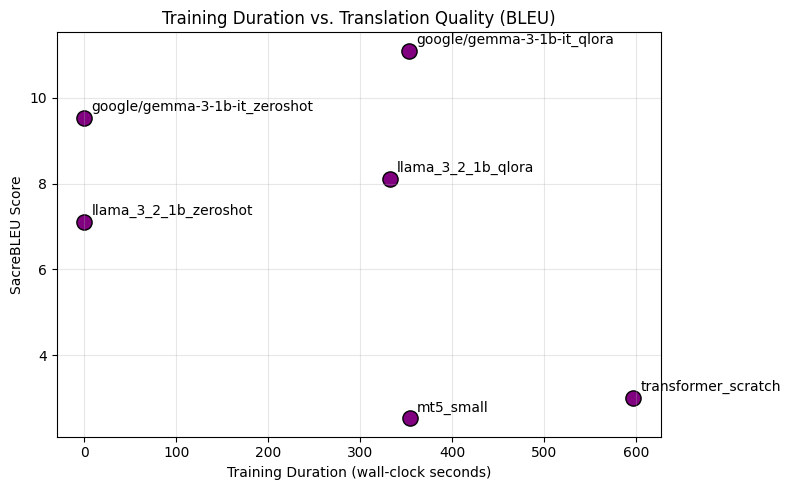

In [4]:
if not df_comp.empty:
    os.makedirs("results/plots", exist_ok=True)
    models = df_comp["Model"].tolist()
    bleu_scores = df_comp["BLEU"].astype(float).tolist()
    chrf_scores = df_comp["chrF"].astype(float).tolist()
    train_times = df_comp["Train Time (s)"].astype(float).tolist()
    latencies = df_comp["Inference (ms/sent)"].astype(float).tolist()

    x = np.arange(len(models))
    width = 0.35

    # 1. Bar Chart: BLEU & chrF Comparison
    plt.figure(figsize=(10, 5))
    plt.bar(x - width/2, bleu_scores, width, label='SacreBLEU', color='royalblue')
    plt.bar(x + width/2, chrf_scores, width, label='chrF', color='darkorange')
    plt.xticks(x, models, rotation=15, ha='right')
    plt.ylabel('Score')
    plt.title('Translation Performance: SacreBLEU and chrF across Models')
    plt.legend()
    plt.grid(axis='y', alpha=0.3)
    plt.tight_layout()
    plt.savefig('results/plots/model_comparison_bleu_chrf.png', dpi=300)
    plt.show()

    # 2. Bar Chart: Inference Latency
    plt.figure(figsize=(8, 4))
    plt.bar(models, latencies, color='teal', width=0.5)
    plt.ylabel('Latency (ms / sentence)')
    plt.title('Inference Latency Comparison on T4 GPU')
    plt.xticks(rotation=15, ha='right')
    plt.grid(axis='y', alpha=0.3)
    plt.tight_layout()
    plt.savefig('results/plots/inference_latency_comparison.png', dpi=300)
    plt.show()

    # 3. Scatter: Training Time vs BLEU
    plt.figure(figsize=(8, 5))
    plt.scatter(train_times, bleu_scores, color='purple', s=120, edgecolors='black')
    for i, txt in enumerate(models):
        plt.annotate(txt, (train_times[i], bleu_scores[i]), xytext=(5, 5), textcoords='offset points')
    plt.xlabel('Training Duration (wall-clock seconds)')
    plt.ylabel('SacreBLEU Score')
    plt.title('Training Duration vs. Translation Quality (BLEU)')
    plt.grid(True, alpha=0.3)
    plt.tight_layout()
    plt.savefig('results/plots/train_time_vs_bleu.png', dpi=300)
    plt.show()

## 5. Programmatic Winner Identification (No Hardcoding)

In [5]:
if not df_comp.empty:
    best_bleu_idx = df_comp["BLEU"].astype(float).idxmax()
    best_chrf_idx = df_comp["chrF"].astype(float).idxmax()
    fastest_inf_idx = df_comp["Inference (ms/sent)"].astype(float).idxmin()

    print("=== Programmatic Evaluation Summary ===")
    print(f"Highest BLEU Score : {df_comp.loc[best_bleu_idx, 'Model']} ({df_comp.loc[best_bleu_idx, 'BLEU']})")
    print(f"Highest chrF Score : {df_comp.loc[best_chrf_idx, 'Model']} ({df_comp.loc[best_chrf_idx, 'chrF']})")
    print(f"Lowest Latency     : {df_comp.loc[fastest_inf_idx, 'Model']} ({df_comp.loc[fastest_inf_idx, 'Inference (ms/sent)']} ms/sent)")

=== Programmatic Evaluation Summary ===
Highest BLEU Score : google/gemma-3-1b-it_qlora (11.1)
Highest chrF Score : google/gemma-3-1b-it_qlora (35.93)
Lowest Latency     : transformer_scratch (21.61 ms/sent)


## 6. Structured Discussion Template for Assignment Report

### A. Impact of Model Size & Pretraining
- **Scratch vs. Pretrained**: *[Discuss how Model A's 11M parameters trained on 50k pairs compares to mT5's 300M and LLaMA's 1B. Highlight whether pretraining provided vocabulary breadth or grammatical fluency.]*

### B. Architectural Paradigm: Encoder-Decoder vs. Decoder-Only
- **Attention Mechanism**: *[Discuss why bidirectional encoding in mT5 differs from causal autoregressive attention in LLaMA/Gemma for translation conditioning.]*
- **Computational Footprint**: *[Discuss inference latency and memory requirements, specifically KV-cache management.]*

### C. Tokenization Efficiency Trade-offs
- **Token Inflation**: *[Discuss observations from the tokenization efficiency table above. Note why English-centric byte-level BPE requires more subwords per Hindi word than large multilingual vocabularies.]*

### D. Adaptation Strategy: Full Fine-Tuning vs. QLoRA
- **Parameter Efficiency**: *[Compare updating 100% of mT5 parameters vs. <2% of LLaMA/Gemma parameters via 4-bit LoRA adapters.]*